In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, confusion_matrix, ConfusionMatrixDisplay,roc_curve, auc)

In [2]:
df = pd.read_csv('star_classification.csv')

In [3]:
df.shape

(100000, 18)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  object 
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int64  
dtypes: float64(10), int64(7),

In [5]:
df.columns

Index(['obj_ID', 'alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'run_ID',
       'rerun_ID', 'cam_col', 'field_ID', 'spec_obj_ID', 'class', 'redshift',
       'plate', 'MJD', 'fiber_ID'],
      dtype='object')

In [6]:
df.dtypes

obj_ID         float64
alpha          float64
delta          float64
u              float64
g              float64
r              float64
i              float64
z              float64
run_ID           int64
rerun_ID         int64
cam_col          int64
field_ID         int64
spec_obj_ID    float64
class           object
redshift       float64
plate            int64
MJD              int64
fiber_ID         int64
dtype: object

In [7]:
df.dtypes

obj_ID         float64
alpha          float64
delta          float64
u              float64
g              float64
r              float64
i              float64
z              float64
run_ID           int64
rerun_ID         int64
cam_col          int64
field_ID         int64
spec_obj_ID    float64
class           object
redshift       float64
plate            int64
MJD              int64
fiber_ID         int64
dtype: object

In [8]:
df.describe()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,redshift,plate,MJD,fiber_ID
count,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.0,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.237665e+18,177.629117,24.135305,21.980468,20.531387,19.645762,19.084854,18.668810,4481.366060,301.0,3.511610,186.130520,5.783882e+18,0.576661,5137.009660,55588.647500,449.312740
std,8.438560e+12,96.502241,19.644665,31.769291,31.750292,1.854760,1.757895,31.728152,1964.764593,0.0,1.586912,149.011073,3.324016e+18,0.730707,2952.303351,1808.484233,272.498404
min,1.237646e+18,0.005528,-18.785328,-9999.000000,-9999.000000,9.822070,9.469903,-9999.000000,109.000000,301.0,1.000000,11.000000,2.995191e+17,-0.009971,266.000000,51608.000000,1.000000
25%,1.237659e+18,127.518222,5.146771,20.352353,18.965230,18.135828,17.732285,17.460677,3187.000000,301.0,2.000000,82.000000,2.844138e+18,0.054517,2526.000000,54234.000000,221.000000
50%,1.237663e+18,180.900700,23.645922,22.179135,21.099835,20.125290,19.405145,19.004595,4188.000000,301.0,4.000000,146.000000,5.614883e+18,0.424173,4987.000000,55868.500000,433.000000
75%,1.237668e+18,233.895005,39.901550,23.687440,22.123767,21.044785,20.396495,19.921120,5326.000000,301.0,5.000000,241.000000,8.332144e+18,0.704154,7400.250000,56777.000000,645.000000
max,1.237681e+18,359.999810,83.000519,32.781390,31.602240,29.571860,32.141470,29.383740,8162.000000,301.0,6.000000,989.000000,1.412694e+19,7.011245,12547.000000,58932.000000,1000.000000


In [9]:
df.head()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


In [10]:
df.tail()


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
99995,1.237679e+18,39.620709,-2.594074,22.16759,22.97586,21.90404,21.30548,20.73569,7778,301,2,581,1.055431e+19,GALAXY,0.000000,9374,57749,438
99996,1.237679e+18,29.493819,19.798874,22.69118,22.38628,20.45003,19.75759,19.41526,7917,301,1,289,8.586351e+18,GALAXY,0.404895,7626,56934,866
99997,1.237668e+18,224.587407,15.700707,21.16916,19.26997,18.20428,17.69034,17.35221,5314,301,4,308,3.112008e+18,GALAXY,0.143366,2764,54535,74
99998,1.237661e+18,212.268621,46.660365,25.35039,21.63757,19.91386,19.07254,18.62482,3650,301,4,131,7.601080e+18,GALAXY,0.455040,6751,56368,470
99999,1.237661e+18,196.896053,49.464643,22.62171,21.79745,20.60115,20.00959,19.28075,3650,301,4,60,8.343152e+18,GALAXY,0.542944,7410,57104,851


In [11]:
df.nunique()


obj_ID          78053
alpha           99999
delta           99999
u               93748
g               92651
r               91901
i               92019
z               92007
run_ID            430
rerun_ID            1
cam_col             6
field_ID          856
spec_obj_ID    100000
class               3
redshift        99295
plate            6284
MJD              2180
fiber_ID         1000
dtype: int64

In [12]:
print(df.duplicated().sum())
df.drop_duplicates(inplace=True)

print(df.isnull().sum())

0
obj_ID         0
alpha          0
delta          0
u              0
g              0
r              0
i              0
z              0
run_ID         0
rerun_ID       0
cam_col        0
field_ID       0
spec_obj_ID    0
class          0
redshift       0
plate          0
MJD            0
fiber_ID       0
dtype: int64


class
GALAXY    59445
STAR      21594
QSO       18961
Name: count, dtype: int64


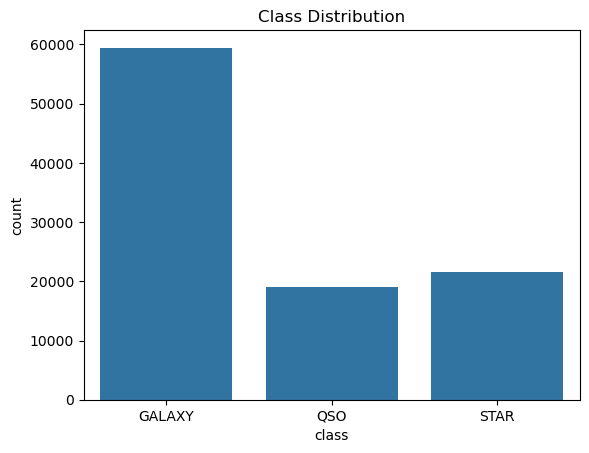

In [13]:
print(df['class'].value_counts())

sns.countplot(x='class', data=df)
plt.title('Class Distribution')
plt.show()

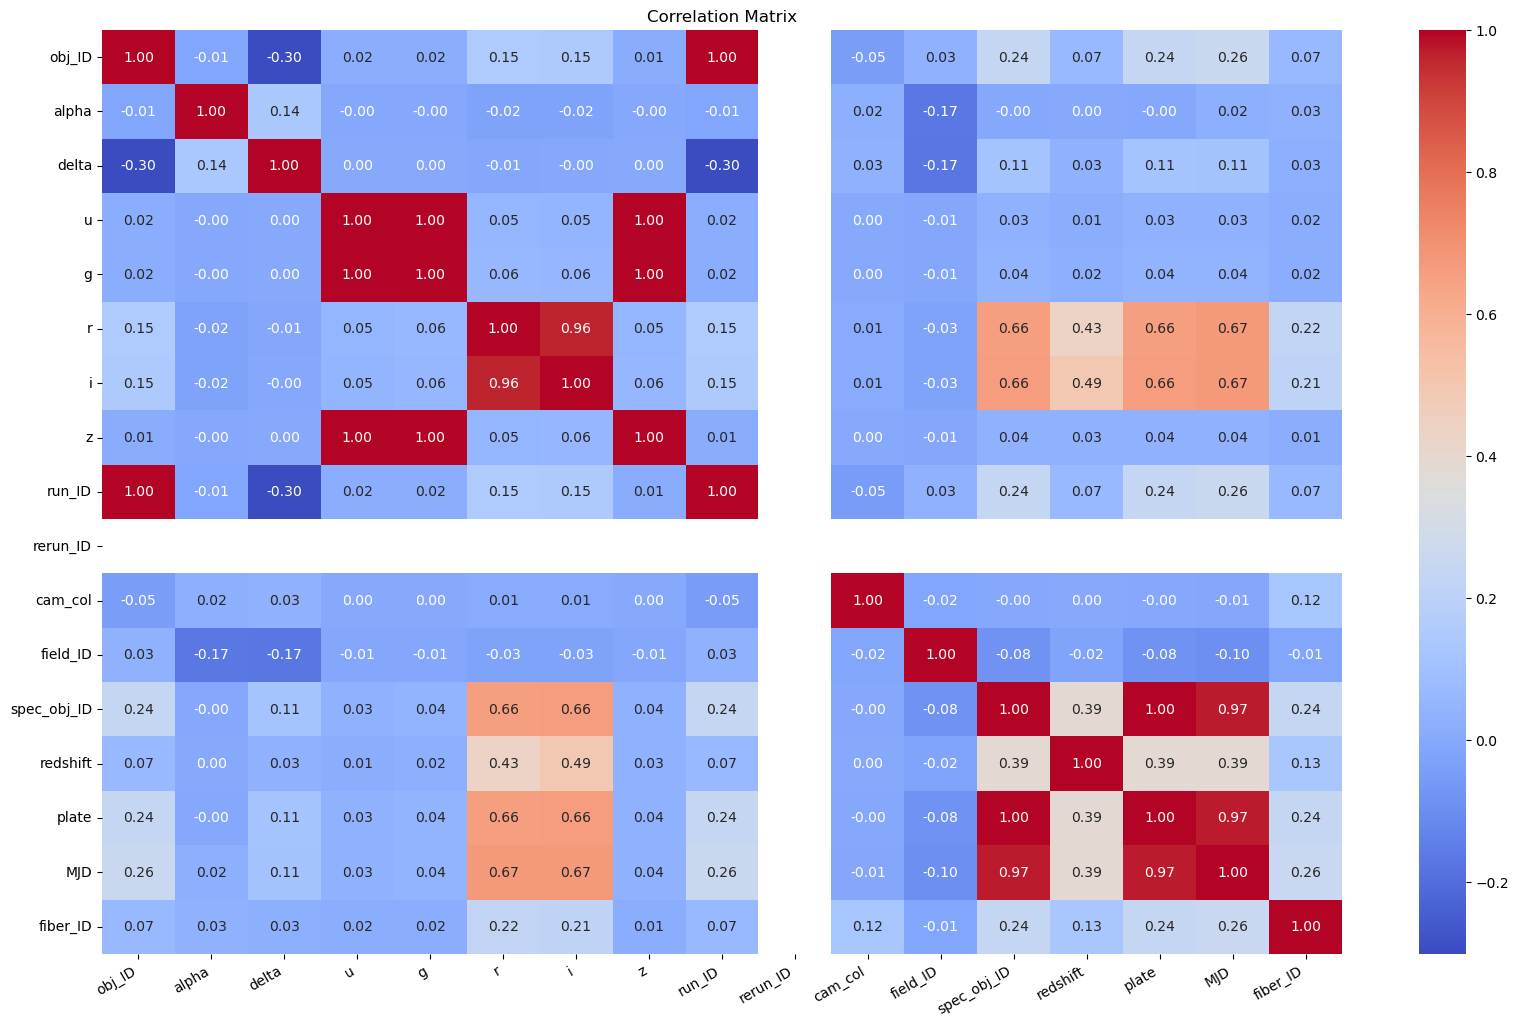

In [14]:
corr_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(20, 12))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.xticks(rotation=30, ha='right')
plt.show()

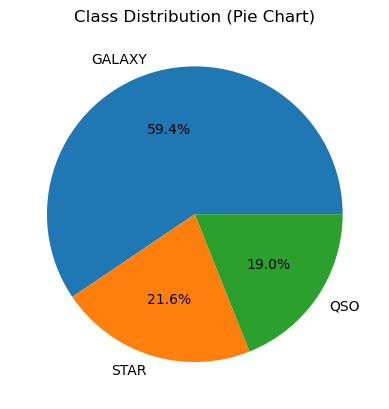

In [15]:
# 1. Pie Chart
df['class'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.ylabel('')
plt.title('Class Distribution (Pie Chart)')
plt.show()

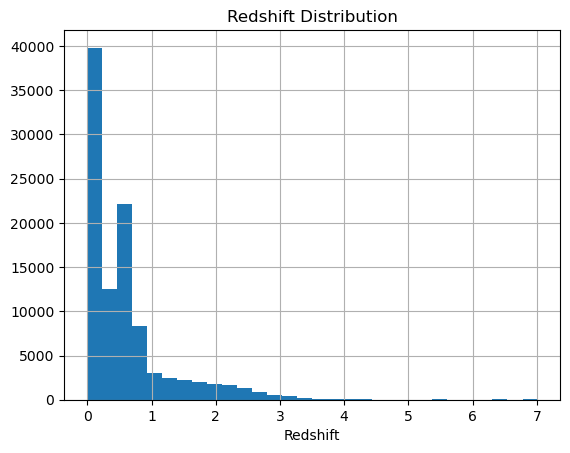

In [16]:
# 2. Histogram
df['redshift'].hist(bins=30)
plt.title('Redshift Distribution')
plt.xlabel('Redshift')
plt.show()

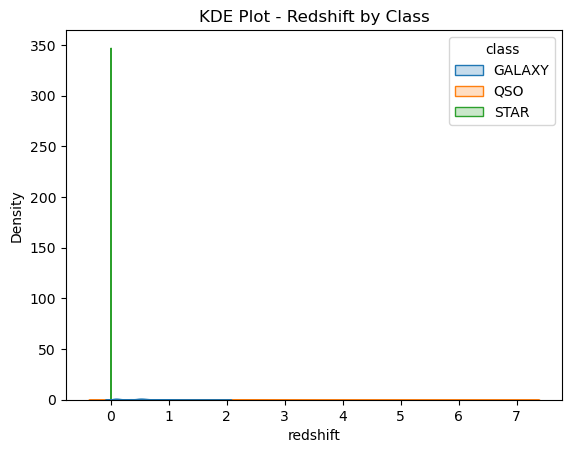

In [17]:
# 3. KDE Plot
sns.kdeplot(data=df, x='redshift', hue='class', fill=True)
plt.title('KDE Plot - Redshift by Class')
plt.show()

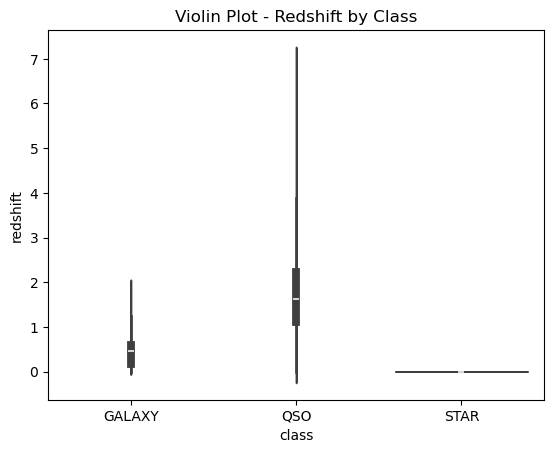

In [18]:
# 4. Violin Plot
sns.violinplot(x='class', y='redshift', data=df)
plt.title('Violin Plot - Redshift by Class')
plt.show()

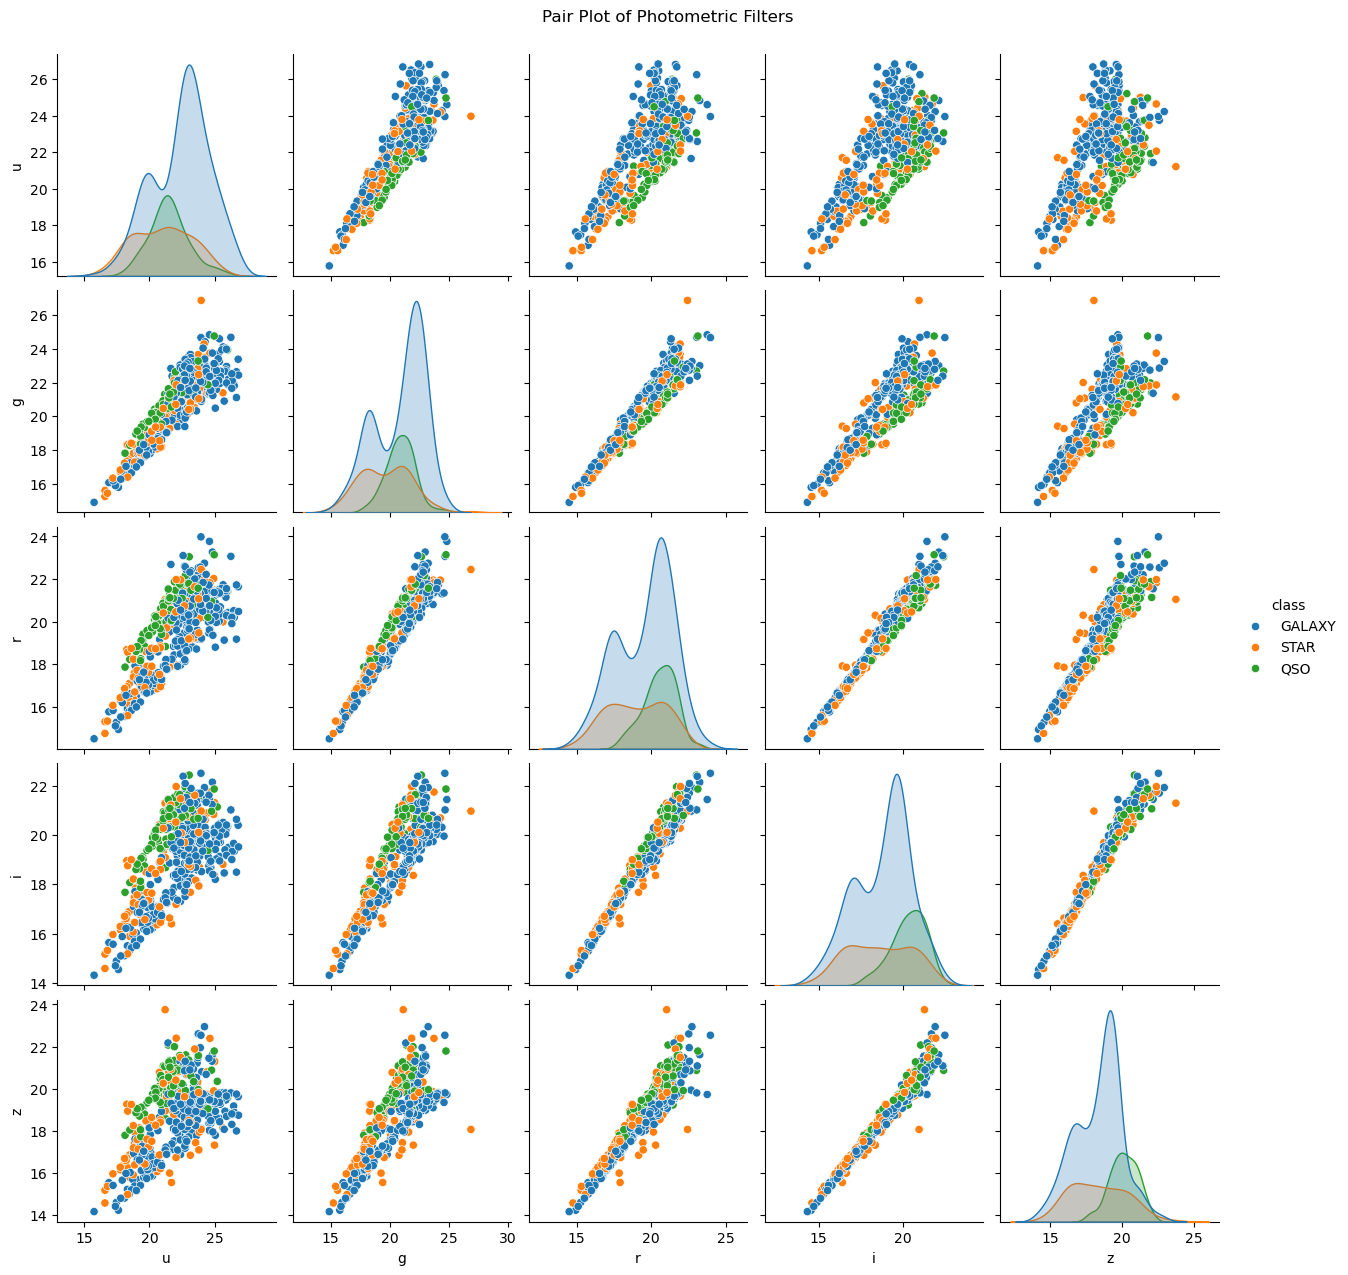

In [19]:
# 5. Pair Plot
sample_df = df.sample(500, random_state=42)
sns.pairplot(sample_df, vars=['u', 'g', 'r', 'i', 'z'], hue='class')
plt.suptitle('Pair Plot of Photometric Filters', y=1.02)
plt.show()

In [20]:
df.drop(columns=['obj_ID', 'spec_obj_ID', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID', 'plate', 'MJD', 'fiber_ID'], inplace=True)

In [21]:
le = LabelEncoder()
df['class'] = le.fit_transform(df['class'])
print("Class Mapping:")
for label, code in zip(le.classes_, le.transform(le.classes_)):
    print(f"  {label} → {int(code)}")

Class Mapping:
  GALAXY → 0
  QSO → 1
  STAR → 2


In [22]:
X = df.drop(columns=['class'])
Y = df['class']
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=42)

In [23]:
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Accuracy:  0.9290
Precision: 0.9279
Recall:    0.9141
F1 Score:  0.9200


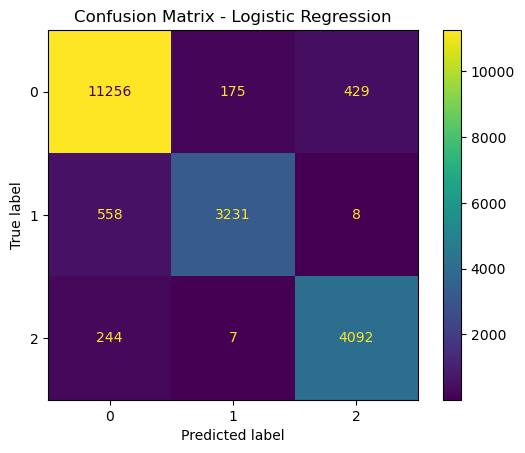

In [24]:
model = LogisticRegression(max_iter=1000, solver='saga')
model.fit(X_train, Y_train)
Y_pred = model.predict(X_test)

print(f"Accuracy:  {accuracy_score(Y_test, Y_pred):.4f}")
print(f"Precision: {precision_score(Y_test, Y_pred, average='macro'):.4f}")
print(f"Recall:    {recall_score(Y_test, Y_pred, average='macro'):.4f}")
print(f"F1 Score:  {f1_score(Y_test, Y_pred, average='macro'):.4f}")

conf_matrix = confusion_matrix(Y_test, Y_pred)
ConfusionMatrixDisplay(conf_matrix).plot()
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

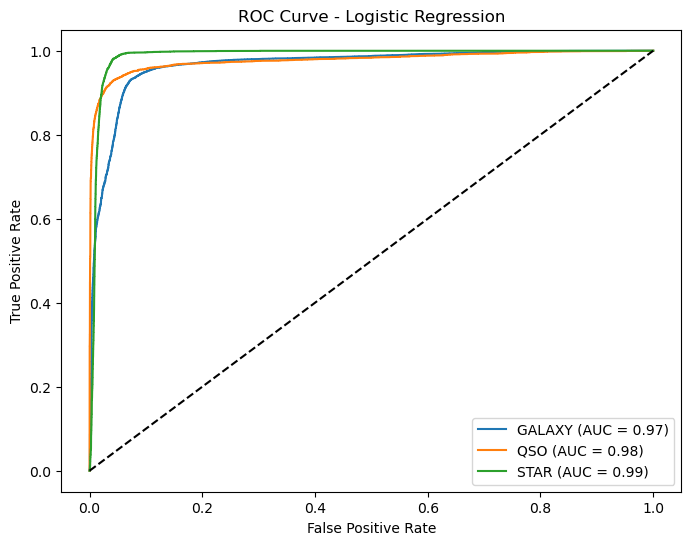

In [25]:
from sklearn.preprocessing import label_binarize

Y_test_bin = label_binarize(Y_test, classes=[0, 1, 2])
Y_prob = model.predict_proba(X_test)

plt.figure(figsize=(8, 6))
for i, class_name in enumerate(le.classes_):
    fpr, tpr, _ = roc_curve(Y_test_bin[:, i], Y_prob[:, i])
    plt.plot(fpr, tpr, label=f'{class_name} (AUC = {auc(fpr, tpr):.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.show()

Accuracy:  0.9646
Precision: 0.9594
Recall:    0.9589
F1 Score:  0.9592


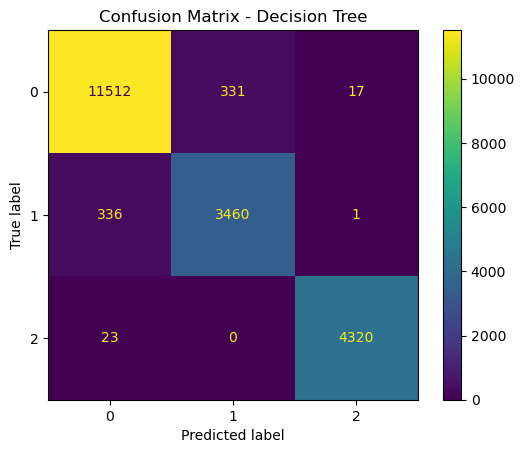

In [26]:
#additional
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, Y_train)
dt_pred = dt_model.predict(X_test)

print(f"Accuracy:  {accuracy_score(Y_test, dt_pred):.4f}")
print(f"Precision: {precision_score(Y_test, dt_pred, average='macro'):.4f}")
print(f"Recall:    {recall_score(Y_test, dt_pred, average='macro'):.4f}")
print(f"F1 Score:  {f1_score(Y_test, dt_pred, average='macro'):.4f}")

conf_matrix_dt = confusion_matrix(Y_test, dt_pred)
ConfusionMatrixDisplay(conf_matrix_dt).plot()
plt.title('Confusion Matrix - Decision Tree')
plt.show()

In [27]:
print(" MODEL COMPARISON ")
print(f"Logistic Regression Accuracy: {accuracy_score(Y_test, Y_pred):.4f}")
print(f"Decision Tree Accuracy:       {accuracy_score(Y_test, dt_pred):.4f}")

 MODEL COMPARISON 
Logistic Regression Accuracy: 0.9290
Decision Tree Accuracy:       0.9646
